<a href="https://colab.research.google.com/github/adityasptra14/retail-sales-and-rfm-analysis/blob/main/Retail_Sales_and_RFM_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Mengatur tampilan grafik agar terlihat bersih dan profesional
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# Membuat dataset transaksi ritel realistis (5.000 baris transaksi)
np.random.seed(42)
n_rows = 5000

kategori_produk = {
    'Elektronik & Aksesoris': (150000, 2500000),
    'Pakaian & Fashion': (75000, 600000),
    'Kebutuhan Rumah Tangga': (30000, 450000),
    'Kesehatan & Kecantikan': (40000, 350000),
    'Olahraga & Hobi': (100000, 1200000)
}

kategori_pilihan = np.random.choice(list(kategori_produk.keys()), size=n_rows, p=[0.20, 0.30, 0.25, 0.15, 0.10])
harga_satuan = [np.random.randint(kategori_produk[k][0], kategori_produk[k][1]) for k in kategori_pilihan]

df = pd.DataFrame({
    'Invoice_ID': [f'INV-{10000 + i}' for i in range(n_rows)],
    'Customer_ID': [f'CUST-{np.random.randint(1001, 1800)}' for _ in range(n_rows)],
    'Order_Date': pd.to_datetime('2025-01-01') + pd.to_timedelta(np.random.randint(0, 365, size=n_rows), unit='D'),
    'Category': kategori_pilihan,
    'Quantity': np.random.choice([1, 2, 3, 4, 5], size=n_rows, p=[0.5, 0.25, 0.15, 0.06, 0.04]),
    'Unit_Price': harga_satuan,
    'Discount_Pct': np.random.choice([0.0, 0.05, 0.10, 0.20, 0.30], size=n_rows, p=[0.45, 0.25, 0.15, 0.10, 0.05])
})

# Sengaja menambahkan sedikit "data kotor" (duplikat & nilai kosong) untuk simulasi Data Cleaning
df.loc[np.random.choice(df.index, 35, replace=False), 'Customer_ID'] = np.nan
df = pd.concat([df, df.sample(20)], ignore_index=True)

print(f"Ukuran data awal: {df.shape[0]} baris dan {df.shape[1]} kolom")
df.head()

Ukuran data awal: 5020 baris dan 7 kolom


,Invoice_ID,Customer_ID,Order_Date,Category,Quantity,Unit_Price,Discount_Pct
0,INV-10000,CUST-1536,2025-04-29,Pakaian & Fashion,1,422186,0.00
1,INV-10001,CUST-1291,2025-06-27,Olahraga & Hobi,1,337103,0.00
2,INV-10002,CUST-1168,2025-01-20,Kebutuhan Rumah Tangga,1,274754,0.00
3,INV-10003,CUST-1621,2025-02-05,Kebutuhan Rumah Tangga,3,195637,0.05
4,INV-10004,CUST-1428,2025-12-01,Elektronik & Aksesoris,1,2336394,0.10


In [12]:
# 1. Cek jumlah data kosong dan duplikat
print("Jumlah data kosong per kolom:\n", df.isnull().sum())
print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")

# 2. Menghapus baris tanpa Customer_ID dan menghapus duplikat
df_clean = df.dropna(subset=['Customer_ID']).drop_duplicates().copy()

# 3. Membuat kolom metrik bisnis baru (Gross Sales, Net Revenue, dan Estimasi Profit)
df_clean['Gross_Sales'] = df_clean['Quantity'] * df_clean['Unit_Price']
df_clean['Discount_Amount'] = df_clean['Gross_Sales'] * df_clean['Discount_Pct']
df_clean['Net_Revenue'] = df_clean['Gross_Sales'] - df_clean['Discount_Amount']

# Asumsi HPP (Harga Pokok Penjualan / COGS) adalah 72% dari harga normal
df_clean['COGS'] = df_clean['Gross_Sales'] * 0.72
df_clean['Net_Profit'] = df_clean['Net_Revenue'] - df_clean['COGS']
df_clean['Year_Month'] = df_clean['Order_Date'].dt.to_period('M').astype(str)

print(f"\nUkuran data setelah dibersihkan: {df_clean.shape[0]} transaksi valid.")
df_clean[['Invoice_ID', 'Customer_ID', 'Category', 'Net_Revenue', 'Net_Profit']].head()

Jumlah data kosong per kolom:
 Invoice_ID       0
Customer_ID     35
Order_Date       0
Category         0
Quantity         0
Unit_Price       0
Discount_Pct     0
dtype: int64

Jumlah baris duplikat: 20

Ukuran data setelah dibersihkan: 4965 transaksi valid.


,Invoice_ID,Customer_ID,Category,Net_Revenue,Net_Profit
0,INV-10000,CUST-1536,Pakaian & Fashion,422186.00,118212.08
1,INV-10001,CUST-1291,Olahraga & Hobi,337103.00,94388.84
2,INV-10002,CUST-1168,Kebutuhan Rumah Tangga,274754.00,76931.12
3,INV-10003,CUST-1621,Kebutuhan Rumah Tangga,557565.45,134989.53
4,INV-10004,CUST-1428,Elektronik & Aksesoris,2102754.60,420550.92


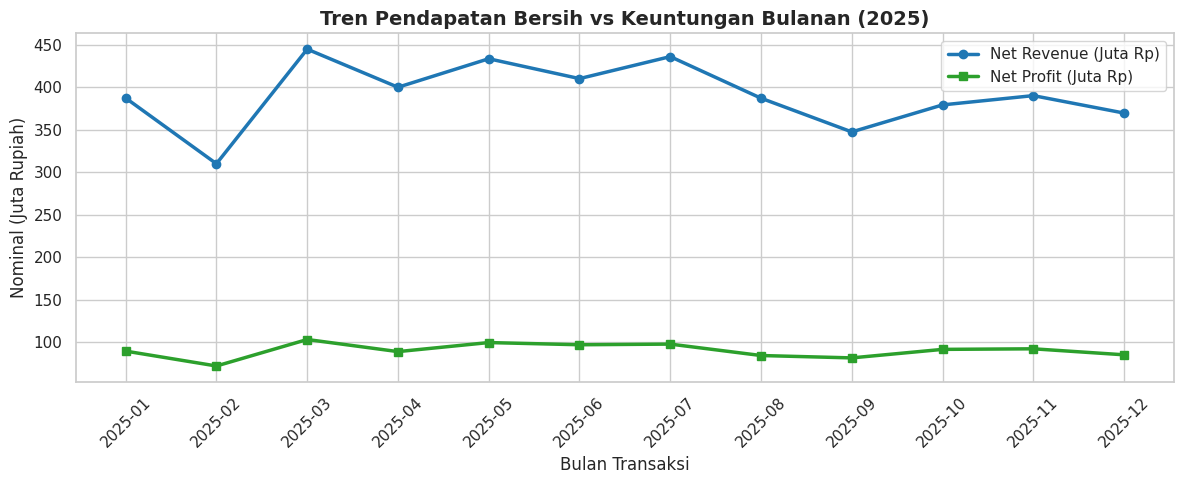

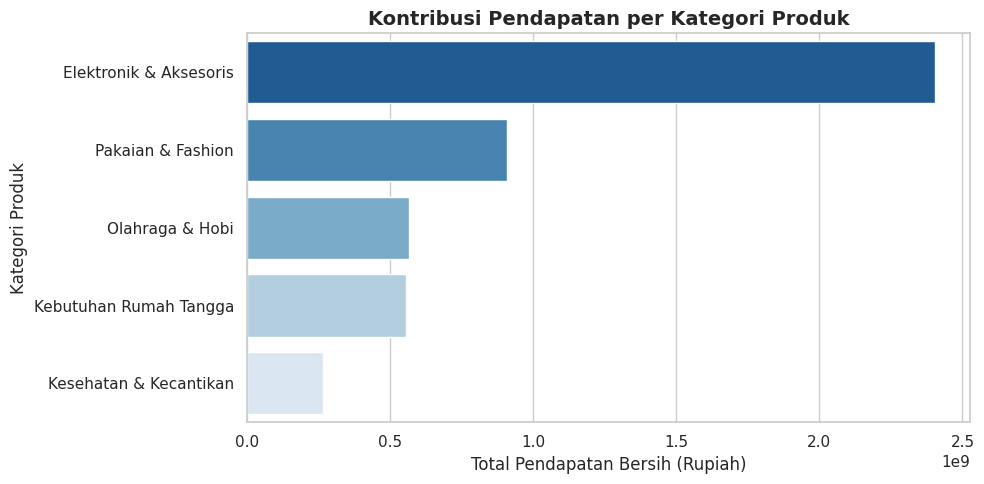

,Category,Total_Revenue,Total_Profit,Total_Orders,Profit_Margin_Pct
0,Elektronik & Aksesoris,2.405145e+09,5.512150e+08,1023,22.918162
4,Pakaian & Fashion,9.075861e+08,2.123135e+08,1460,23.393211
3,Olahraga & Hobi,5.640631e+08,1.305253e+08,472,23.140188
1,Kebutuhan Rumah Tangga,5.538266e+08,1.284572e+08,1256,23.194479
2,Kesehatan & Kecantikan,2.668973e+08,6.180187e+07,754,23.155678


In [13]:
# Grafik 1: Tren Pendapatan dan Profit Bulanan
monthly_perf = df_clean.groupby('Year_Month')[['Net_Revenue', 'Net_Profit']].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_perf['Year_Month'], monthly_perf['Net_Revenue'] / 1e6, marker='o', linewidth=2.5, label='Net Revenue (Juta Rp)', color='#1f77b4')
plt.plot(monthly_perf['Year_Month'], monthly_perf['Net_Profit'] / 1e6, marker='s', linewidth=2.5, label='Net Profit (Juta Rp)', color='#2ca02c')
plt.title('Tren Pendapatan Bersih vs Keuntungan Bulanan (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Bulan Transaksi')
plt.ylabel('Nominal (Juta Rupiah)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('tren_bulanan.png', dpi=300) # Menyimpan gambar untuk diunggah ke README GitHub
plt.show()

# Grafik 2: Perbandingan Omzet vs Margin Keuntungan per Kategori Produk
cat_perf = df_clean.groupby('Category').agg(
    Total_Revenue=('Net_Revenue', 'sum'),
    Total_Profit=('Net_Profit', 'sum'),
    Total_Orders=('Invoice_ID', 'count')
).reset_index()
cat_perf['Profit_Margin_Pct'] = (cat_perf['Total_Profit'] / cat_perf['Total_Revenue']) * 100
cat_perf = cat_perf.sort_values(by='Total_Revenue', ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=cat_perf, x='Total_Revenue', y='Category', hue='Category', palette='Blues_r', legend=False)
plt.title('Kontribusi Pendapatan per Kategori Produk', fontsize=14, fontweight='bold')
plt.xlabel('Total Pendapatan Bersih (Rupiah)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.savefig('performa_kategori.png', dpi=300)
plt.show()

cat_perf

In [14]:
discount_impact = df_clean.groupby('Discount_Pct').agg(
    Jumlah_Transaksi=('Invoice_ID', 'count'),
    Rata_Rata_Revenue=('Net_Revenue', 'mean'),
    Rata_Rata_Profit=('Net_Profit', 'mean'),
    Total_Profit=('Net_Profit', 'sum')
).reset_index()

discount_impact['Discount_Label'] = (discount_impact['Discount_Pct'] * 100).astype(int).astype(str) + '%'
print("Evaluasi Profitabilitas Berdasarkan Tingkat Diskon:")
display(discount_impact[['Discount_Label', 'Jumlah_Transaksi', 'Rata_Rata_Revenue', 'Rata_Rata_Profit', 'Total_Profit']])

Evaluasi Profitabilitas Berdasarkan Tingkat Diskon:


,Discount_Label,Jumlah_Transaksi,Rata_Rata_Revenue,Rata_Rata_Profit,Total_Profit
0,0%,2179,990430.885727,277320.648004,6.042817e+08
1,5%,1274,992768.209576,240354.408634,3.062115e+08
2,10%,761,920926.347043,184185.269409,1.401650e+08
3,20%,488,797663.637705,79766.363770,3.892599e+07
4,30%,263,701511.111027,-20043.174601,-5.271355e+06


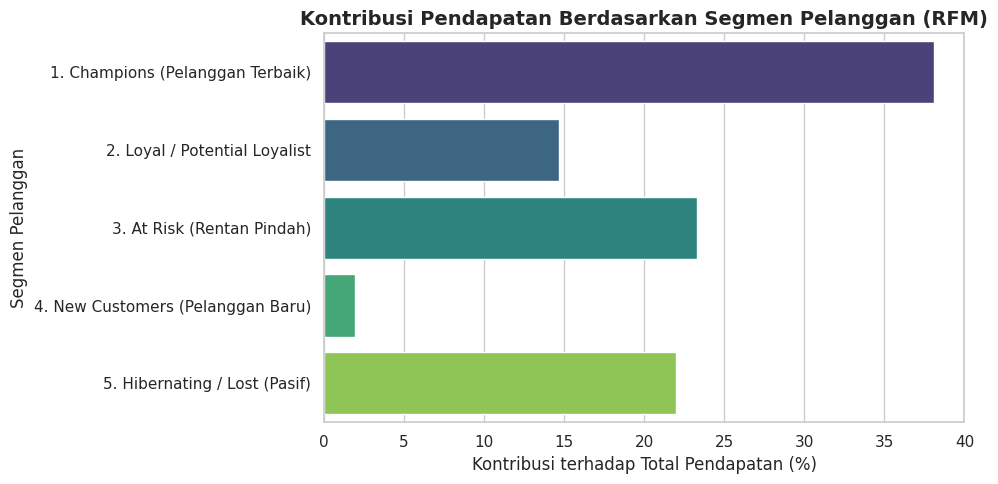

,Segment,Jumlah_Pelanggan,Rata_Recency_Hari,Rata_Frequency,Total_Pendapatan,Persentase_Pelanggan (%),Persentase_Pendapatan (%)
0,1. Champions (Pelanggan Terbaik),189,19.201058,8.671958,1.791704e+09,23.7,38.1
1,2. Loyal / Potential Loyalist,156,19.557692,6.192308,6.910476e+08,19.6,14.7
2,3. At Risk (Rentan Pindah),145,85.875862,7.875862,1.095612e+09,18.2,23.3
3,4. New Customers (Pelanggan Baru),26,9.076923,3.423077,8.742199e+07,3.3,1.9
4,5. Hibernating / Lost (Pasif),281,100.807829,4.017794,1.031732e+09,35.3,22.0


In [15]:
# Menentukan tanggal acuan analisis (H+1 dari transaksi terakhir di dataset)
snapshot_date = df_clean['Order_Date'].max() + dt.timedelta(days=1)

# Menghitung nilai Recency, Frequency, dan Monetary untuk setiap pelanggan
rfm = df_clean.groupby('Customer_ID').agg({
    'Order_Date': lambda x: (snapshot_date - x.max()).days, # Recency
    'Invoice_ID': 'nunique',                                # Frequency
    'Net_Revenue': 'sum'                                    # Monetary
}).reset_index()

rfm.rename(columns={
    'Order_Date': 'Recency',
    'Invoice_ID': 'Frequency',
    'Net_Revenue': 'Monetary'
}, inplace=True)

# Memberikan skor 1 sampai 4 menggunakan kuartil (semakin kecil Recency semakin bagus = skor 4)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4]).astype(int)

# Mengelompokkan pelanggan ke dalam segmen bisnis
def segmentasi_pelanggan(row):
    if row['R_Score'] >= 3 and row['F_Score'] >= 3 and row['M_Score'] >= 3:
        return '1. Champions (Pelanggan Terbaik)'
    elif row['R_Score'] >= 3 and row['F_Score'] >= 2:
        return '2. Loyal / Potential Loyalist'
    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return '3. At Risk (Rentan Pindah)'
    elif row['R_Score'] == 4 and row['F_Score'] == 1:
        return '4. New Customers (Pelanggan Baru)'
    else:
        return '5. Hibernating / Lost (Pasif)'

rfm['Segment'] = rfm.apply(segmentasi_pelanggan, axis=1)

# Ringkasan tiap segmen
segment_summary = rfm.groupby('Segment').agg(
    Jumlah_Pelanggan=('Customer_ID', 'count'),
    Rata_Recency_Hari=('Recency', 'mean'),
    Rata_Frequency=('Frequency', 'mean'),
    Total_Pendapatan=('Monetary', 'sum')
).reset_index()

segment_summary['Persentase_Pelanggan (%)'] = (segment_summary['Jumlah_Pelanggan'] / rfm.shape[0] * 100).round(1)
segment_summary['Persentase_Pendapatan (%)'] = (segment_summary['Total_Pendapatan'] / rfm['Monetary'].sum() * 100).round(1)

# Visualisasi Distribusi Segmen Pelanggan
plt.figure(figsize=(10, 5))
sns.barplot(data=segment_summary, x='Persentase_Pendapatan (%)', y='Segment', hue='Segment', palette='viridis', legend=False)
plt.title('Kontribusi Pendapatan Berdasarkan Segmen Pelanggan (RFM)', fontsize=14, fontweight='bold')
plt.xlabel('Kontribusi terhadap Total Pendapatan (%)')
plt.ylabel('Segmen Pelanggan')
plt.tight_layout()
plt.savefig('segmentasi_rfm.png', dpi=300)
plt.show()

display(segment_summary)